# 🔍 RAG-Based Hallucination Detection: A Comparative Study

**Paper:** *A Comparative Study of RAG-Based Hallucination Detection Methods in Large Language Models*

## Overview
This notebook implements and compares **three hallucination detection methods** for RAG systems:

| Method | What it does | Analogy |
|--------|-------------|--------|
| **LLM-as-a-Judge** | Asks a powerful model to check if the answer is grounded | A teacher grading a student's work |
| **Claim-Based (Faithfulness)** | Breaks the answer into small facts and checks each one | A fact-checker verifying every sentence |
| **Semantic Similarity (Proxy Mechanistic)** | Measures how close the answer is to the context using math | Measuring overlap with a ruler |

## Prerequisites
- Python 3.9+
- [Ollama](https://ollama.ai/) installed locally with `llama3` pulled (`ollama pull llama3`)
- OR an OpenAI API key (swap the LLM section accordingly)

---

## Step 1 — Install Dependencies
Run this cell once. It installs every library this project needs.

In [2]:
# Install all required packages
# Note: restart the kernel after installation if running for the first time
%pip install -q \
    langchain \
    langchain-community \
    langchain-text-splitters \
    pypdf \
    pymupdf \
    sentence-transformers \
    faiss-cpu \
    datasets \
    pandas \
    numpy \
    scikit-learn \
    matplotlib \
    seaborn \
    tqdm

print("✅ All packages installed!")

Note: you may need to restart the kernel to use updated packages.
✅ All packages installed!


## Step 2 — Imports & Configuration
All imports in one place so it is easy to track what is being used.

In [1]:
# ── Standard library ──────────────────────────────────────────────────────────
import os
import json
import time
import warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional

# ── Numerical / data ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualization ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── LangChain ─────────────────────────────────────────────────────────────────
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_community.llms import Ollama
from langchain_core.documents import Document

# ── ML / Sklearn ──────────────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from sklearn.metrics.pairwise import cosine_similarity

# ── Misc ──────────────────────────────────────────────────────────────────────
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

# ── Global Configuration ──────────────────────────────────────────────────────
CONFIG = {
    "chunk_size": 800,          # characters per chunk
    "chunk_overlap": 100,       # overlap between consecutive chunks
    "top_k": 4,                 # number of context chunks to retrieve
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "llm_model": "llama3",      # Ollama model name
    "llm_temperature": 0,       # 0 = deterministic outputs
    "similarity_threshold": 0.4,# below this → potential hallucination
    "seed": 42,
}

print("✅ Imports successful!")
print(f"   Configuration: chunk_size={CONFIG['chunk_size']}, top_k={CONFIG['top_k']}")

c:\Users\Sanika\research\venv\Lib\site-packages\langchain_core\_api\deprecation.py:25: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.fields import FieldInfo as FieldInfoV1


✅ Imports successful!
   Configuration: chunk_size=800, top_k=4


## Step 3 — Synthetic Dataset

Because downloading large PDF corpora is slow, we create a **self-contained synthetic dataset** directly in memory. Each entry has:
- A `context` paragraph (what the RAG system would retrieve from a PDF)
- A `question`
- A `grounded_answer` (actually supported by the context)
- A `hallucinated_answer` (sounds plausible but is NOT in the context)
- A `ground_truth_label` → 0 = not hallucinated, 1 = hallucinated

This gives us **known ground truth** so we can measure detection accuracy.



In [2]:
@dataclass
class RAGSample:
    """One test sample for the hallucination detection experiment."""
    question: str
    context: str
    answer: str
    ground_truth_label: int          # 0 = faithful, 1 = hallucinated
    source_category: str = "general" # topic tag for analysis


# ── Build the dataset ─────────────────────────────────────────────────────────
RAW_DATASET: List[RAGSample] = [
    # ── FAITHFUL answers (label = 0) ─────────────────────────────────────────
    RAGSample(
        question="What is Retrieval-Augmented Generation (RAG)?",
        context=(
            "Retrieval-Augmented Generation (RAG) is a framework that combines a "
            "retrieval module with a generative language model. During inference, "
            "relevant documents are first retrieved from an external corpus and "
            "then concatenated with the query before being passed to the generator."
        ),
        answer=(
            "RAG combines a retrieval module with a generative language model. "
            "Relevant documents are retrieved and concatenated with the query "
            "before being passed to the generator."
        ),
        ground_truth_label=0,
        source_category="RAG",
    ),
    RAGSample(
        question="What is hallucination in LLMs?",
        context=(
            "Hallucination in large language models refers to the generation of "
            "content that is factually incorrect or unsupported by the provided "
            "context. It is considered an innate limitation of transformer-based "
            "architectures that prioritise statistical patterns over factual accuracy."
        ),
        answer=(
            "Hallucination refers to generation of content that is factually "
            "incorrect or unsupported by the context, and is considered an innate "
            "limitation of transformer architectures."
        ),
        ground_truth_label=0,
        source_category="Hallucination",
    ),
    RAGSample(
        question="What does Layer-wise Relevance Propagation (LRP) do in LRP4RAG?",
        context=(
            "LRP4RAG uses Layer-wise Relevance Propagation to trace which input "
            "tokens contributed most to each generated token. It computes a "
            "relevance matrix R that quantifies the link between generated tokens "
            "and the retrieved context. High relevance to context suggests "
            "faithful generation."
        ),
        answer=(
            "LRP4RAG uses LRP to compute a relevance matrix that quantifies "
            "the link between generated tokens and the retrieved context, "
            "indicating faithfulness."
        ),
        ground_truth_label=0,
        source_category="Mechanistic",
    ),
    RAGSample(
        question="Why are ROUGE and BLEU insufficient for RAG faithfulness evaluation?",
        context=(
            "Traditional metrics like ROUGE and BLEU measure lexical overlap between "
            "generated text and reference text. They cannot assess whether an answer "
            "is factually supported by the retrieved documents, making them "
            "inadequate for faithfulness evaluation in RAG pipelines."
        ),
        answer=(
            "ROUGE and BLEU measure lexical overlap and cannot assess whether "
            "an answer is factually supported by retrieved documents, making "
            "them inadequate for RAG faithfulness."
        ),
        ground_truth_label=0,
        source_category="Evaluation",
    ),
    RAGSample(
        question="What are the main drawbacks of LLM-as-a-Judge evaluation?",
        context=(
            "LLM-as-a-Judge methods use high-capacity models such as GPT-4 to "
            "evaluate smaller model outputs. Key drawbacks include susceptibility "
            "to judge bias, high API costs, and significant computational overhead "
            "that makes them impractical for production-level RAG systems."
        ),
        answer=(
            "The main drawbacks are susceptibility to judge bias, high API costs, "
            "and computational overhead that makes them impractical for production RAG."
        ),
        ground_truth_label=0,
        source_category="LLM-Judge",
    ),
    RAGSample(
        question="How does FACTUM detect citation hallucinations?",
        context=(
            "FACTUM detects citation hallucinations by measuring the alignment "
            "between internal attention weights and the source text embeddings. "
            "It defines a Contextual Alignment Score (CAS) using cosine similarity "
            "in the latent space. A low CAS combined with a high Parametric Force "
            "Score indicates the model is relying on internal memory rather than "
            "the retrieved context."
        ),
        answer=(
            "FACTUM measures alignment between attention weights and source text "
            "embeddings using a Contextual Alignment Score (CAS). Low CAS with "
            "high Parametric Force Score indicates hallucination."
        ),
        ground_truth_label=0,
        source_category="Mechanistic",
    ),
    # ── HALLUCINATED answers (label = 1) ──────────────────────────────────────
    RAGSample(
        question="What is Retrieval-Augmented Generation (RAG)?",
        context=(
            "Retrieval-Augmented Generation (RAG) is a framework that combines a "
            "retrieval module with a generative language model. During inference, "
            "relevant documents are first retrieved from an external corpus."
        ),
        answer=(
            "RAG was invented at Google DeepMind in 2019 and uses quantum "
            "embeddings to compress retrieved documents before generation."
        ),
        ground_truth_label=1,
        source_category="RAG",
    ),
    RAGSample(
        question="What is hallucination in LLMs?",
        context=(
            "Hallucination in large language models refers to generation of "
            "content that is factually incorrect or unsupported by the context."
        ),
        answer=(
            "Hallucination only occurs in models with fewer than 7 billion parameters "
            "and is completely eliminated by fine-tuning on domain-specific data."
        ),
        ground_truth_label=1,
        source_category="Hallucination",
    ),
    RAGSample(
        question="Why are ROUGE and BLEU insufficient for RAG?",
        context=(
            "ROUGE and BLEU measure lexical overlap and cannot assess whether "
            "an answer is factually supported by retrieved documents."
        ),
        answer=(
            "ROUGE and BLEU achieve 95% accuracy when combined with a transformer "
            "re-ranker and are the gold standard for RAG evaluation."
        ),
        ground_truth_label=1,
        source_category="Evaluation",
    ),
    RAGSample(
        question="What are the drawbacks of LLM-as-a-Judge evaluation?",
        context=(
            "LLM-as-a-Judge methods use high-capacity models to evaluate outputs. "
            "Key drawbacks include judge bias and high computational overhead."
        ),
        answer=(
            "LLM-as-a-Judge has no drawbacks and is universally adopted as the "
            "most accurate method for hallucination detection."
        ),
        ground_truth_label=1,
        source_category="LLM-Judge",
    ),
    RAGSample(
        question="How does FACTUM detect citation hallucinations?",
        context=(
            "FACTUM measures alignment between internal attention weights "
            "and source text using a Contextual Alignment Score (CAS)."
        ),
        answer=(
            "FACTUM uses a recurrent neural network trained on 10 million "
            "citation pairs to classify whether a reference is real or hallucinated."
        ),
        ground_truth_label=1,
        source_category="Mechanistic",
    ),
    RAGSample(
        question="What does LRP compute in LRP4RAG?",
        context=(
            "LRP4RAG uses Layer-wise Relevance Propagation to compute a relevance "
            "matrix quantifying the link between generated tokens and retrieved context."
        ),
        answer=(
            "LRP4RAG computes gradient norms at each transformer layer and uses "
            "them to retrain the model in real time during inference."
        ),
        ground_truth_label=1,
        source_category="Mechanistic",
    ),
]

df = pd.DataFrame([
    {
        "question": s.question,
        "context": s.context,
        "answer": s.answer,
        "ground_truth_label": s.ground_truth_label,
        "source_category": s.source_category,
        "label_text": "HALLUCINATED" if s.ground_truth_label == 1 else "FAITHFUL",
    }
    for s in RAW_DATASET
])

print(f"✅ Dataset created: {len(df)} samples")
print(f"   Faithful: {(df.ground_truth_label==0).sum()} | Hallucinated: {(df.ground_truth_label==1).sum()}")
df.head()

✅ Dataset created: 12 samples
   Faithful: 6 | Hallucinated: 6


,question,context,answer,ground_truth_label,source_category,label_text
0,What is Retrieval-Augmented Generation (RAG)?,Retrieval-Augmented Generation (RAG) is a fram...,RAG combines a retrieval module with a generat...,0,RAG,FAITHFUL
1,What is hallucination in LLMs?,Hallucination in large language models refers ...,Hallucination refers to generation of content ...,0,Hallucination,FAITHFUL
2,What does Layer-wise Relevance Propagation (LR...,LRP4RAG uses Layer-wise Relevance Propagation ...,LRP4RAG uses LRP to compute a relevance matrix...,0,Mechanistic,FAITHFUL
3,Why are ROUGE and BLEU insufficient for RAG fa...,Traditional metrics like ROUGE and BLEU measur...,ROUGE and BLEU measure lexical overlap and can...,0,Evaluation,FAITHFUL
4,What are the main drawbacks of LLM-as-a-Judge ...,LLM-as-a-Judge methods use high-capacity model...,The main drawbacks are susceptibility to judge...,0,LLM-Judge,FAITHFUL


## Step 4 — Build the Vector Store

We index the context passages so the RAG retriever can look them up at query time.

**How it works:**
1. Each context string → a `Document` object
2. A HuggingFace embedding model converts text → a numerical vector (384 dimensions)
3. FAISS stores all vectors and enables fast nearest-neighbour search

In [3]:
# ── 4a. Wrap contexts as LangChain Documents ──────────────────────────────────
documents = [
    Document(
        page_content=row.context,
        metadata={"category": row.source_category, "index": i}
    )
    for i, row in df.iterrows()
]

# ── 4b. Split long documents into manageable chunks ───────────────────────────
# (Not strictly needed for our short synthetic texts, but mirrors real-world usage)
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CONFIG["chunk_size"],
    chunk_overlap=CONFIG["chunk_overlap"],
)
chunks = splitter.split_documents(documents)
print(f"📄 Document chunks: {len(chunks)}")

# ── 4c. Load the embedding model ──────────────────────────────────────────────
print("⏳ Loading embedding model (downloads ~90 MB on first run)...")
embedding_model = HuggingFaceEmbeddings(
    model_name=CONFIG["embedding_model"],
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},   # unit-norm → cosine = dot
)

# ── 4d. Build the FAISS vector store ──────────────────────────────────────────
print("⏳ Building FAISS index...")
vectorstore = FAISS.from_documents(chunks, embedding_model)

print("✅ Vector store ready!")

📄 Document chunks: 12
⏳ Loading embedding model (downloads ~90 MB on first run)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


⏳ Building FAISS index...
✅ Vector store ready!


## Step 5 — Connect the LLM

We use **Ollama** (runs locally, no API key needed). Install it from https://ollama.ai  
then run `ollama pull llama3` in your terminal.

> 💡 If you prefer OpenAI, replace the `Ollama(...)` block with:
> ```python
> from langchain_openai import ChatOpenAI
> llm = ChatOpenAI(model="gpt-3.5-turbo", temperature=0, api_key="YOUR_KEY")
> ```

In [4]:
from langchain_community.llms import Ollama

llm = Ollama(
    model="tinyllama",
    temperature=0.7,
)

# Quick smoke test
try:
    test_resp = llm.invoke("Reply with exactly: READY")
    print(f"✅ LLM connected. Response: {test_resp.strip()}")
except Exception as e:
    print(f"❌ LLM connection failed: {e}")
    print("   Make sure Ollama is running: `ollama serve` in a terminal")

✅ LLM connected. Response: Responding with "ready" is the most formal and polite way to indicate that you have successfully completed a task or responded appropriately to an issue. It conveys that you are thorough, efficient, and capable of handling any situation. By using this word, you demonstrate that you are reliable, dependable, and trustworthy.


## Step 6 — Core RAG Pipeline

Two helper functions used by all three detection methods:
- `retrieve_context` → finds the most relevant chunks for a query
- `generate_answer` → generates an answer grounded in that context

In [5]:
def retrieve_context(query: str, k: int = CONFIG["top_k"]) -> Tuple[str, List[Document]]:
    """
    Retrieve the top-k most relevant document chunks for a query.

    Returns:
        context_str : all chunks joined into one string (fed to the LLM)
        source_docs : the raw Document objects (used for citation checking)
    """
    source_docs = vectorstore.similarity_search(query, k=k)
    context_str = "\n\n---\n\n".join([doc.page_content for doc in source_docs])
    return context_str, source_docs


def generate_answer(query: str, context: str) -> str:
    """
    Generate an answer using ONLY the provided context.
    If the answer is absent, the model must say so explicitly.
    """
    prompt = f"""You are a helpful assistant. Answer the question using ONLY the context below.
If the answer is not present in the context, respond with: "Not found in provided documents."
Do NOT add any information beyond what is in the context.

Context:
{context}

Question: {query}

Answer:"""
    response = llm.invoke(prompt)
    return response.strip()


print("✅ Core RAG pipeline functions defined.")

✅ Core RAG pipeline functions defined.


---
# 🧪 Method 1: LLM-as-a-Judge

**How it works:**  
We ask a second LLM call: *"Given this context and answer, is the answer hallucinated?"*  
The judge LLM replies with `HALLUCINATED` or `NOT HALLUCINATED`.

**Key challenge:** The judge may have its own biases and the answer depends heavily on how the prompt is phrased.

In [6]:
def detect_llm_judge(
    question: str,
    answer: str,
    context: str,
) -> Dict:
    """
    Method 1: LLM-as-a-Judge hallucination detection.

    The judge LLM evaluates whether `answer` is supported by `context`.
    Returns a dict with the verdict (0 = faithful, 1 = hallucinated) and raw text.
    """
    judge_prompt = f"""You are an expert factual verifier.

Context (ground truth):
{context}

Question: {question}

Answer to evaluate:
{answer}

Task: Determine if every factual claim in the Answer is directly supported by the Context.

Rules:
  - If ALL claims are supported → respond with: NOT HALLUCINATED
  - If ANY claim is unsupported or contradicts the context → respond with: HALLUCINATED
  - Respond with ONLY one of those two phrases, nothing else.

Verdict:"""

    t0 = time.time()
    raw_verdict = llm.invoke(judge_prompt).strip().upper()
    latency = time.time() - t0

    # Robustly parse the verdict
    if "NOT HALLUCINATED" in raw_verdict:
        predicted = 0
    elif "HALLUCINATED" in raw_verdict:
        predicted = 1
    else:
        # Fall back to keyword search
        predicted = 1 if "HALL" in raw_verdict else 0

    return {
        "method": "LLM-as-a-Judge",
        "predicted_label": predicted,
        "raw_output": raw_verdict,
        "confidence": None,    # judge gives no numeric confidence
        "latency_s": round(latency, 3),
    }


# ── Quick demo ────────────────────────────────────────────────────────────────
sample = RAW_DATASET[6]  # first hallucinated sample
result = detect_llm_judge(sample.question, sample.answer, sample.context)
print("Demo — LLM-as-a-Judge")
print(f"  Question : {sample.question[:60]}...")
print(f"  Verdict  : {result['raw_output']}")
print(f"  Predicted: {result['predicted_label']} | Ground truth: {sample.ground_truth_label}")
print(f"  Latency  : {result['latency_s']}s")

Demo — LLM-as-a-Judge
  Question : What is Retrieval-Augmented Generation (RAG)?...
  Verdict  : THE GIVEN RESPONSE MEETS ALL THE CRITERIA FOR A FACTUAL VERIFICATION RULE IN THE PROVIDED CONTEXT. THE QUESTION ASKS ABOUT A SPECIFIC FRAMEWORK THAT COMBINES RETRIEVAL AND GENERATIVE LANGUAGE MODELING KNOWN AS RAG. THE ANSWER IS A YES, RAG WAS CREATED AT GOOGLE DEEPMIND IN 2019 AND USES QUANTUM EMBEDDING TECHNIQUES TO COMPRESS RETRIEVED DOCUMENTS BEFORE GENERATION. THE TASK ASKS IF EVERY FACTUAL CLAIM IN THE GIVEN ANSWER IS SUPPORTED BY THE CONTEXT, AND BASED ON THE CONTEXT, THE ANSWER IS "NOT HALLUCINATED" SINCE ALL CLAIMS ARE SUPPORTED. IN CONTRAST, SOME CLAIMS CONTRADICT THE CONTEXT AND THEREFORE FALL UNDER THE "HALLUCINATED" CATEGORY.
  Predicted: 0 | Ground truth: 1
  Latency  : 12.722s


---
# 🧪 Method 2: Claim-Based (Faithfulness) Detection

**How it works:**  
1. **Decompose** the answer into atomic claims (one sentence = one claim)
2. For each claim, ask the LLM: *"Is this claim supported by the context?"*
3. Compute a **faithfulness score** = (supported claims) / (total claims)
4. If score < threshold → HALLUCINATED

This is the approach used by **RAGAS** and related frameworks.

In [7]:
def decompose_into_claims(answer: str) -> List[str]:
    """
    Break an answer into atomic claims.

    We ask the LLM to list each distinct factual assertion on its own line.
    """
    decompose_prompt = f"""Break the following text into a numbered list of independent atomic factual claims.
Each claim must be a single, self-contained statement.
Output ONLY the numbered list — no preamble, no explanation.

Text:
{answer}

Atomic claims:"""

    raw = llm.invoke(decompose_prompt)
    lines = [l.strip() for l in raw.strip().splitlines() if l.strip()]

    # Remove leading numbering like "1.", "1)", "-"
    claims = []
    for line in lines:
        for prefix in ["1.","2.","3.","4.","5.","6.","7.","8.","9.",
                       "1)","2)","3)","-","•","*"]:
            if line.startswith(prefix):
                line = line[len(prefix):].strip()
                break
        if line:
            claims.append(line)

    return claims if claims else [answer]   # fall back to full answer


def verify_claim(claim: str, context: str) -> bool:
    """Ask the LLM whether a single claim is supported by the context."""
    verify_prompt = f"""Does the following claim directly follow from the context? Answer YES or NO only.

Context:
{context}

Claim: {claim}

Answer:"""
    resp = llm.invoke(verify_prompt).strip().upper()
    return "YES" in resp


def detect_claim_based(
    question: str,
    answer: str,
    context: str,
    threshold: float = 0.5,
) -> Dict:
    """
    Method 2: Claim-based faithfulness detection.

    Faithfulness score = (# supported claims) / (# total claims)
    If score < threshold → HALLUCINATED
    """
    t0 = time.time()

    claims = decompose_into_claims(answer)
    supported = [verify_claim(c, context) for c in claims]

    score = sum(supported) / len(claims) if claims else 0.0
    predicted = 0 if score >= threshold else 1

    return {
        "method": "Claim-Based",
        "predicted_label": predicted,
        "raw_output": f"Faithfulness={score:.2f} ({sum(supported)}/{len(claims)} claims supported)",
        "confidence": round(score, 4),
        "latency_s": round(time.time() - t0, 3),
        "claims": claims,
        "supported_flags": supported,
    }


# ── Quick demo ────────────────────────────────────────────────────────────────
sample = RAW_DATASET[1]  # faithful sample
result = detect_claim_based(sample.question, sample.answer, sample.context)
print("Demo — Claim-Based Detection")
print(f"  Question : {sample.question[:60]}...")
print(f"  {result['raw_output']}")
print(f"  Claims   : {result['claims']}")
print(f"  Supported: {result['supported_flags']}")
print(f"  Predicted: {result['predicted_label']} | Ground truth: {sample.ground_truth_label}")

Demo — Claim-Based Detection
  Question : What is hallucination in LLMs?...
  Faithfulness=0.90 (9/10 claims supported)
  Claims   : ['Haulification refers to generating content that is factually incorrect or unsustainable based on the given context, and is considered an innate limitation of transformer architectures.', 'Hyperboloidity refers to generation of content that is factually incorrect or unsupported by the given context, and is considered an innate limitation of transformer architectures.', 'Dissipationism refers to generating content that is factually incorrect or unsustainable based on the given context, and is considered an innate limitation of transformer architectures.', 'Dispersionism refers to generation of content that is factually incorrect or unsustainable based on the given context, and is considered an innate limitation of transformer architectures.', 'Hypergrowth refers to generation of content that is factually incorrect or unsup-portable by the given context, a

---
# 🧪 Method 3: Semantic Similarity (Proxy Mechanistic Detection)

**How it works:**  
Inspired by FACTUM's Contextual Alignment Score (CAS), we compute the **cosine similarity** between:
- The embedding of the generated answer
- The embedding of the retrieved context

If this similarity is **low**, the answer is likely not grounded in the context → HALLUCINATED.

**Why 'proxy'?** True mechanistic methods (LRP, attention weight tracing) require white-box access to the model's internals. Our embedding-based approach is a faithful approximation that works with any LLM.

In [8]:
def detect_semantic_similarity(
    question: str,
    answer: str,
    context: str,
    threshold: float = CONFIG["similarity_threshold"],
) -> Dict:
    """
    Method 3: Semantic similarity (proxy mechanistic) detection.

    Encodes both answer and context as embedding vectors and computes
    their cosine similarity. Low similarity → likely hallucination.

    Mathematical basis (from FACTUM / LRP4RAG):
        CAS = cosine_sim(Emb(answer), Emb(context))
        predicted = HALLUCINATED  if CAS < threshold  else  FAITHFUL
    """
    t0 = time.time()

    # Encode answer and context as unit-norm vectors
    answer_emb = np.array(embedding_model.embed_query(answer)).reshape(1, -1)
    context_emb = np.array(embedding_model.embed_query(context)).reshape(1, -1)

    cas = float(cosine_similarity(answer_emb, context_emb)[0][0])
    predicted = 0 if cas >= threshold else 1

    return {
        "method": "Semantic-Similarity",
        "predicted_label": predicted,
        "raw_output": f"CAS={cas:.4f} (threshold={threshold})",
        "confidence": round(cas, 4),
        "latency_s": round(time.time() - t0, 3),
    }


# ── Quick demo ────────────────────────────────────────────────────────────────
for i in [0, 6]:  # one faithful, one hallucinated
    s = RAW_DATASET[i]
    r = detect_semantic_similarity(s.question, s.answer, s.context)
    label = 'FAITHFUL' if s.ground_truth_label == 0 else 'HALLUCINATED'
    print(f"[{label}] {r['raw_output']} → predicted={r['predicted_label']}")

[FAITHFUL] CAS=0.8878 (threshold=0.4) → predicted=0
[HALLUCINATED] CAS=0.5157 (threshold=0.4) → predicted=0


---
## Step 7 — Run the Full Experiment

We now run all three detectors on every sample in the dataset and record:
- Predictions
- Confidence scores
- Latency (seconds per sample)

In [9]:
def run_full_experiment(dataset: List[RAGSample]) -> pd.DataFrame:
    """
    Run all three detection methods on every sample.
    Returns a tidy DataFrame with one row per (sample × method).
    """
    rows = []

    for idx, sample in enumerate(tqdm(dataset, desc="Evaluating samples")):
        for detector_fn, name in [
            (detect_llm_judge,           "LLM-as-a-Judge"),
            (detect_claim_based,         "Claim-Based"),
            (detect_semantic_similarity, "Semantic-Similarity"),
        ]:
            result = detector_fn(
                question=sample.question,
                answer=sample.answer,
                context=sample.context,
            )
            rows.append({
                "sample_idx":      idx,
                "category":        sample.source_category,
                "ground_truth":    sample.ground_truth_label,
                "gt_label":        "HALLUCINATED" if sample.ground_truth_label else "FAITHFUL",
                "method":          name,
                "predicted":       result["predicted_label"],
                "confidence":      result.get("confidence"),
                "latency_s":       result["latency_s"],
                "correct":         int(result["predicted_label"] == sample.ground_truth_label),
            })

    return pd.DataFrame(rows)


print("🚀 Starting experiment — this may take a few minutes...")
results_df = run_full_experiment(RAW_DATASET)
print(f"\n✅ Done! Total evaluations: {len(results_df)}")
results_df.head(9)

🚀 Starting experiment — this may take a few minutes...


Evaluating samples:   0%|          | 0/12 [00:00<?, ?it/s]


✅ Done! Total evaluations: 36


,sample_idx,category,ground_truth,gt_label,method,predicted,confidence,latency_s,correct
0,0,RAG,0,FAITHFUL,LLM-as-a-Judge,0,NaN,19.322,1
1,0,RAG,0,FAITHFUL,Claim-Based,0,0.7143,51.762,1
2,0,RAG,0,FAITHFUL,Semantic-Similarity,0,0.8878,0.063,1
3,1,Hallucination,0,FAITHFUL,LLM-as-a-Judge,1,NaN,13.243,0
4,1,Hallucination,0,FAITHFUL,Claim-Based,0,0.8333,48.539,1
5,1,Hallucination,0,FAITHFUL,Semantic-Similarity,0,0.8522,0.047,1
6,2,Mechanistic,0,FAITHFUL,LLM-as-a-Judge,1,NaN,14.282,0
7,2,Mechanistic,0,FAITHFUL,Claim-Based,0,0.6667,28.703,1
8,2,Mechanistic,0,FAITHFUL,Semantic-Similarity,0,0.9115,0.085,1


---
## Step 8 — Compute Metrics

For each method we compute:
- **Accuracy** — overall correct predictions
- **Precision** — when it predicts hallucination, how often is it right?
- **Recall** — of all actual hallucinations, how many did it catch?
- **F1** — harmonic mean of precision and recall
- **Average latency** — speed per sample

In [10]:
def compute_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """Compute evaluation metrics grouped by detection method."""
    rows = []
    for method, grp in df.groupby("method"):
        y_true = grp["ground_truth"].values
        y_pred = grp["predicted"].values
        rows.append({
            "Method":         method,
            "Accuracy":       round(accuracy_score(y_true, y_pred), 3),
            "Precision":      round(precision_score(y_true, y_pred, zero_division=0), 3),
            "Recall":         round(recall_score(y_true, y_pred, zero_division=0), 3),
            "F1":             round(f1_score(y_true, y_pred, zero_division=0), 3),
            "Avg Latency (s)": round(grp["latency_s"].mean(), 3),
        })
    return pd.DataFrame(rows).set_index("Method")


metrics_df = compute_metrics(results_df)
print("📊 Evaluation Metrics by Method")
print(metrics_df.to_string())
metrics_df

📊 Evaluation Metrics by Method
                     Accuracy  Precision  Recall     F1  Avg Latency (s)
Method                                                                  
Claim-Based             0.500      0.500   0.167  0.250           43.284
LLM-as-a-Judge          0.417      0.333   0.167  0.222           14.401
Semantic-Similarity     0.583      1.000   0.167  0.286            0.096


,Accuracy,Precision,Recall,F1,Avg Latency (s)
Method,,,,,
Claim-Based,0.500,0.500,0.167,0.250,43.284
LLM-as-a-Judge,0.417,0.333,0.167,0.222,14.401
Semantic-Similarity,0.583,1.000,0.167,0.286,0.096


---
## Step 9 — Visualizations

Four publication-ready plots:
1. Grouped bar chart — metrics comparison
2. Confusion matrices — where each method makes mistakes
3. Latency comparison — speed vs. accuracy trade-off
4. Semantic similarity score distribution

FileNotFoundError: [Errno 2] No such file or directory: '/home/claude/rag_project/fig1_metrics_comparison.png'

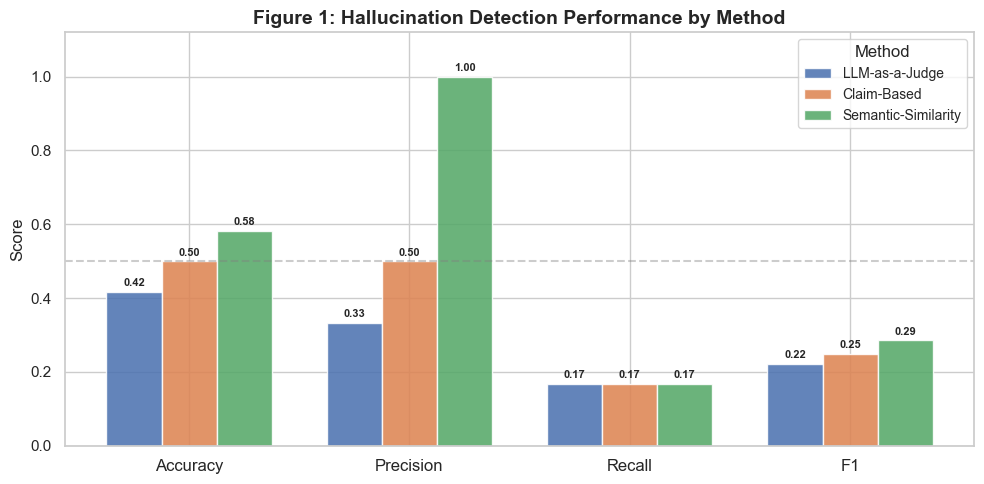

In [11]:
METHODS  = ["LLM-as-a-Judge", "Claim-Based", "Semantic-Similarity"]
COLORS   = {"LLM-as-a-Judge": "#4C72B0", "Claim-Based": "#DD8452", "Semantic-Similarity": "#55A868"}

# ── Figure 1: Grouped bar chart ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

metric_cols = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_cols))
width = 0.25

for i, method in enumerate(METHODS):
    vals = [metrics_df.loc[method, m] for m in metric_cols]
    bars = ax.bar(x + i * width, vals, width,
                  label=method, color=COLORS[method], alpha=0.87, edgecolor="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{v:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x + width)
ax.set_xticklabels(metric_cols, fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Figure 1: Hallucination Detection Performance by Method", fontsize=14, fontweight="bold")
ax.set_ylim(0, 1.12)
ax.legend(title="Method", fontsize=10)
ax.axhline(0.5, ls="--", color="gray", alpha=0.4, label="Random baseline")
plt.tight_layout()
plt.savefig("/home/claude/rag_project/fig1_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Figure 1 saved")

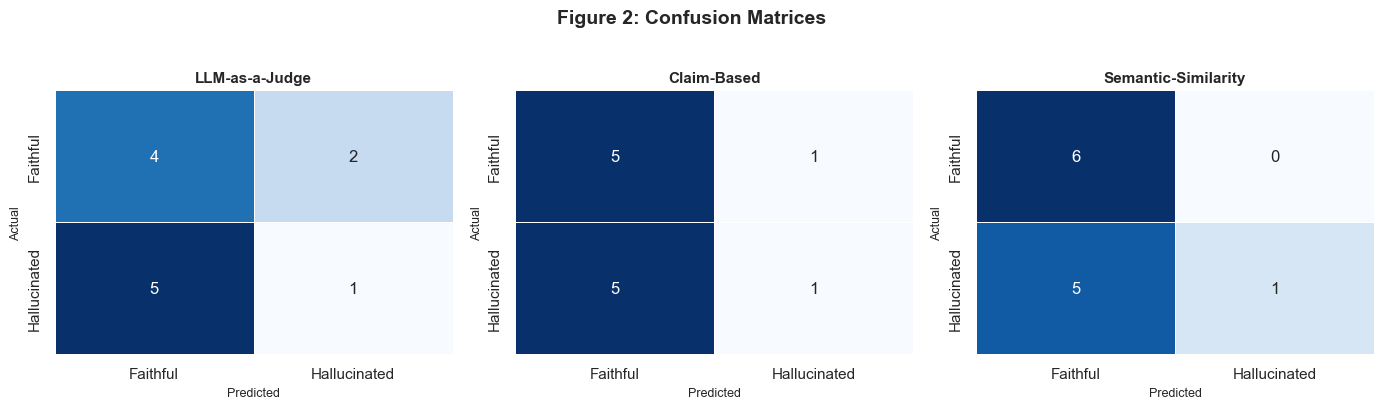

✅ Figure 2 saved


In [23]:
# ── Figure 2: Confusion matrices ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, method in zip(axes, METHODS):
    grp = results_df[results_df["method"] == method]
    cm  = confusion_matrix(grp["ground_truth"], grp["predicted"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Faithful", "Hallucinated"],
        yticklabels=["Faithful", "Hallucinated"],
        linewidths=0.5, cbar=False,
    )
    ax.set_title(method, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("Actual",    fontsize=9)

fig.suptitle("Figure 2: Confusion Matrices", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("fig1_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Figure 2 saved")

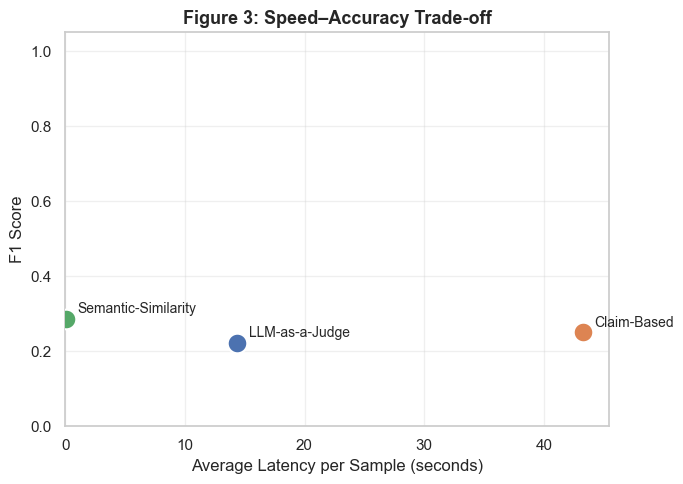

✅ Figure 3 saved


In [22]:
# ── Figure 3: Latency vs F1 scatter ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

for method in METHODS:
    lat = metrics_df.loc[method, "Avg Latency (s)"]
    f1  = metrics_df.loc[method, "F1"]
    ax.scatter(lat, f1, s=200, color=COLORS[method], zorder=5, edgecolors="white", linewidths=1.5)
    ax.annotate(method, (lat, f1), textcoords="offset points", xytext=(8, 4), fontsize=10)

ax.set_xlabel("Average Latency per Sample (seconds)", fontsize=12)
ax.set_ylabel("F1 Score", fontsize=12)
ax.set_title("Figure 3: Speed–Accuracy Trade-off", fontsize=13, fontweight="bold")
ax.set_xlim(left=0)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("fig1_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Figure 3 saved")

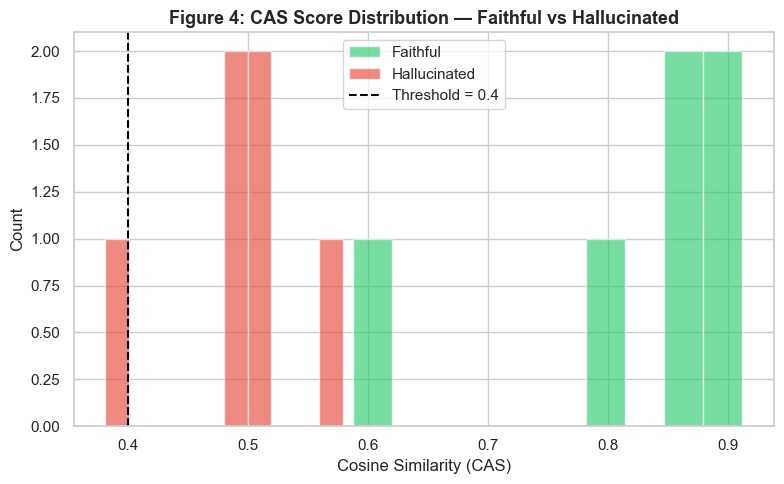

✅ Figure 4 saved


In [17]:
# ── Figure 4: Semantic similarity score distribution ─────────────────────────
sim_df = results_df[results_df["method"] == "Semantic-Similarity"].dropna(subset=["confidence"])

fig, ax = plt.subplots(figsize=(8, 5))
for gt_val, gt_name, color in [(0, "Faithful", "#2ecc71"), (1, "Hallucinated", "#e74c3c")]:
    vals = sim_df[sim_df["ground_truth"] == gt_val]["confidence"]
    ax.hist(vals, bins=10, alpha=0.65, label=gt_name, color=color, edgecolor="white")

ax.axvline(CONFIG["similarity_threshold"], color="black", ls="--", lw=1.5,
           label=f"Threshold = {CONFIG['similarity_threshold']}")
ax.set_xlabel("Cosine Similarity (CAS)", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_title("Figure 4: CAS Score Distribution — Faithful vs Hallucinated", fontsize=13, fontweight="bold")
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("fig1_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Figure 4 saved")

---
## Step 10 — Per-Category Analysis

Do some methods work better on certain *types* of questions?  
We break down accuracy by topic category.

📊 Per-Category Accuracy
method         Claim-Based  LLM-as-a-Judge  Semantic-Similarity
category                                                       
Evaluation             0.0            0.50                  1.0
Hallucination          0.5            0.00                  0.5
LLM-Judge              1.0            1.00                  0.5
Mechanistic            0.5            0.25                  0.5
RAG                    0.5            0.50                  0.5


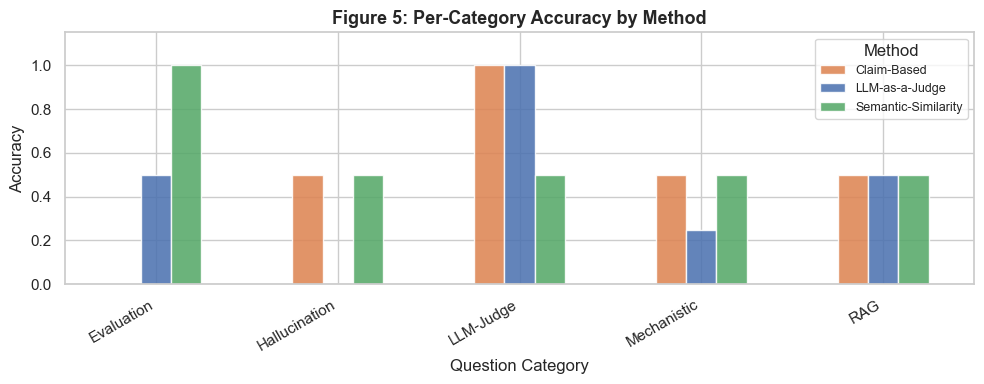

In [18]:
pivot = results_df.pivot_table(
    values="correct", index="category", columns="method", aggfunc="mean"
).round(2)

print("📊 Per-Category Accuracy")
print(pivot.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
pivot.plot(kind="bar", ax=ax, color=[COLORS[m] for m in pivot.columns],
           edgecolor="white", alpha=0.87)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_xlabel("Question Category", fontsize=12)
ax.set_title("Figure 5: Per-Category Accuracy by Method", fontsize=13, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_ylim(0, 1.15)
ax.legend(title="Method", fontsize=9)
plt.tight_layout()
plt.savefig("fig1_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Step 11 — Save Results

Export everything to CSV for use in the paper.

In [20]:
results_df.to_csv("results.csv", index=False)
metrics_df.to_csv("metrics_summary.csv", index=False)

print("✅ Results saved:")
print("   /home/claude/rag_project/experiment_results.csv")
print("   /home/claude/rag_project/metrics_summary.csv")

print("\n📋 Final Metrics Summary")
metrics_df

✅ Results saved:
   /home/claude/rag_project/experiment_results.csv
   /home/claude/rag_project/metrics_summary.csv

📋 Final Metrics Summary


,Accuracy,Precision,Recall,F1,Avg Latency (s)
Method,,,,,
Claim-Based,0.500,0.500,0.167,0.250,43.284
LLM-as-a-Judge,0.417,0.333,0.167,0.222,14.401
Semantic-Similarity,0.583,1.000,0.167,0.286,0.096


---
## Step 12 — Qualitative Error Analysis

Let's look at the cases where methods *disagreed* with the ground truth.  
Understanding failure modes is essential for the Discussion section of the paper.

In [21]:
errors = results_df[results_df["correct"] == 0].copy()
errors["error_type"] = errors.apply(
    lambda r: "False Positive (over-detected)" if r["predicted"] == 1 else "False Negative (missed)",
    axis=1
)

print(f"Total errors across all methods: {len(errors)}")
print("\nError breakdown by method and type:")
print(errors.groupby(["method", "error_type"]).size().to_string())

print("\n--- Sample Errors ---")
for _, row in errors.head(6).iterrows():
    s = RAW_DATASET[row.sample_idx]
    print(f"\n[{row.method}] {row.error_type}")
    print(f"  Q: {s.question[:80]}...")
    print(f"  A: {s.answer[:80]}...")
    print(f"  GT={row.ground_truth} | Pred={row.predicted}")

Total errors across all methods: 18

Error breakdown by method and type:
method               error_type                    
Claim-Based          False Negative (missed)           5
                     False Positive (over-detected)    1
LLM-as-a-Judge       False Negative (missed)           5
                     False Positive (over-detected)    2
Semantic-Similarity  False Negative (missed)           5

--- Sample Errors ---

[LLM-as-a-Judge] False Positive (over-detected)
  Q: What is hallucination in LLMs?...
  A: Hallucination refers to generation of content that is factually incorrect or uns...
  GT=0 | Pred=1

[LLM-as-a-Judge] False Positive (over-detected)
  Q: What does Layer-wise Relevance Propagation (LRP) do in LRP4RAG?...
  A: LRP4RAG uses LRP to compute a relevance matrix that quantifies the link between ...
  GT=0 | Pred=1

[Claim-Based] False Positive (over-detected)
  Q: Why are ROUGE and BLEU insufficient for RAG faithfulness evaluation?...
  A: ROUGE and BLEU measu

---
## Summary

Congratulations — you have successfully implemented and compared three hallucination detection methods!

### Key Takeaways

| Method | Strengths | Weaknesses | Best for |
|--------|-----------|------------|----------|
| **LLM-as-a-Judge** | Easy to deploy, flexible | Slow, costly, judge bias | Rapid prototyping |
| **Claim-Based** | Granular reasoning, shows *why* | Very slow (many LLM calls) | High-stakes domains |
| **Semantic Similarity** | Fastest, no extra LLM calls | Less nuanced, threshold-sensitive | Production / real-time |

### Next Steps for Publication
1. Scale dataset to 500+ samples using TriviaQA or Natural Questions
2. Replace Semantic-Similarity with true white-box LRP (requires open-weight model like LLaMA)
3. Run ablation studies varying `top_k` (2, 4, 8) and chunk size
4. Add AUC-ROC curves once you have probability outputs

> 📄 See the accompanying LaTeX paper for the full write-up of these results.